# КП — Методи обчислювального інтелекту

**Барабаш Катерина · ТВ-61мп · Варіант 2**

| Частина | Задача | Кроки |
|---|---|---|
| 1. Нечітка система | касові збори фільму | 1–4 |
| 2. Нейро-нечітка модель | прогноз service_cost_kuah | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | 9–11 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## Частина 1. Нечітка система

### 1. Підсистема

In [2]:
TERMS = ["низький", "середній", "високий"]

def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for var in (x, y, z):
        var.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
             for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

def infer(ranges, table, method, x_val, y_val):
    sim = fuzzy_system(*ranges, table, method)
    sim.input["x"] = x_val
    sim.input["y"] = y_val
    sim.compute()
    return sim.output["z"]

print("Функцію fuzzy_system побудовано.")

Функцію fuzzy_system побудовано.


### 2. Виведення за Мамдані

In [3]:
# Межі змінних зі README варіанта 2
RANGES_11 = ((0, 10), (0, 10), (0, 10))    # script quality, actor quality, director quality
RANGES_12 = ((0, 200), (0, 10), (0, 10))   # budget M$, special effects, spectacle
RANGES_13 = ((0, 10), (0, 10), (0, 500))   # director quality, spectacle, box office M$

# Таблиці правил — однакові для всіх трьох підсистем (README variant 2)
BASE_TABLE = [
    ["низький",  "низький",  "середній"],
    ["низький",  "середній", "високий"],
    ["середній", "високий",  "високий"],
]
TABLE_11 = [row[:] for row in BASE_TABLE]
TABLE_12 = [row[:] for row in BASE_TABLE]
TABLE_13 = [row[:] for row in BASE_TABLE]

# Тестова точка: 1.1 x=8.5, y=2.5; 1.2 x=100, y=9.5
out_11 = infer(RANGES_11, TABLE_11, "centroid", 8.5, 2.5)
out_12 = infer(RANGES_12, TABLE_12, "centroid", 100, 9.5)
out_13_centroid = infer(RANGES_13, TABLE_13, "centroid", out_11, out_12)
out_13_mom      = infer(RANGES_13, TABLE_13, "mom",      out_11, out_12)

print(f"1.1  (якість сценарію=8.5, гра акторів=2.5)  →  режисерська якість: {out_11:.4f} балів")
print(f"1.2  (бюджет=100 млн$, спецефекти=9.5)        →  видовищність: {out_12:.4f} балів")
print(f"1.3  центроїд:            {out_13_centroid:.4f} млн $")
print(f"1.3  середнє максимумів:  {out_13_mom:.4f} млн $")

1.1  (якість сценарію=8.5, гра акторів=2.5)  →  режисерська якість: 5.3460 балів
1.2  (бюджет=100 млн$, спецефекти=9.5)        →  видовищність: 7.3824 балів
1.3  центроїд:            276.9289 млн $
1.3  середнє максимумів:  250.0000 млн $


In [4]:
# Сила дев'яти правил 1.3 у тестовій точці
lo_x, hi_x = RANGES_13[0]
lo_y, hi_y = RANGES_13[1]
mid_x = (lo_x + hi_x) / 2
mid_y = (lo_y + hi_y) / 2

u_x = np.linspace(lo_x, hi_x, 201)
u_y = np.linspace(lo_y, hi_y, 201)

abcs_x = {"низький": [lo_x, lo_x, mid_x], "середній": [lo_x, mid_x, hi_x], "високий": [mid_x, hi_x, hi_x]}
abcs_y = {"низький": [lo_y, lo_y, mid_y], "середній": [lo_y, mid_y, hi_y], "високий": [mid_y, hi_y, hi_y]}

mu_x = {t: float(fuzz.interp_membership(u_x, fuzz.trimf(u_x, abc), out_11)) for t, abc in abcs_x.items()}
mu_y = {t: float(fuzz.interp_membership(u_y, fuzz.trimf(u_y, abc), out_12)) for t, abc in abcs_y.items()}

print(f"x={out_11:.4f}  μ: {', '.join(f'{t}={v:.4f}' for t,v in mu_x.items())}")
print(f"y={out_12:.4f}  μ: {', '.join(f'{t}={v:.4f}' for t,v in mu_y.items())}")
print()

rows_s = []
for i, tx in enumerate(TERMS):
    for j, ty in enumerate(TERMS):
        rows_s.append({"x": tx, "y": ty, "z": TABLE_13[i][j], "сила": min(mu_x[tx], mu_y[ty])})

df_s = pd.DataFrame(rows_s).sort_values("сила", ascending=False).reset_index(drop=True)
print(df_s.to_string())

x=5.3460  μ: низький=0.0000, середній=0.9308, високий=0.0692
y=7.3824  μ: низький=0.0000, середній=0.5235, високий=0.4765

          x         y         z      сила
0  середній  середній  середній  0.523529
1  середній   високий   високий  0.476471
2   високий  середній   високий  0.069203
3   високий   високий   високий  0.069203
4   низький   низький   низький  0.000000
5   низький  середній   низький  0.000000
6   низький   високий  середній  0.000000
7  середній   низький   низький  0.000000
8   високий   низький  середній  0.000000


### 3. Поверхня

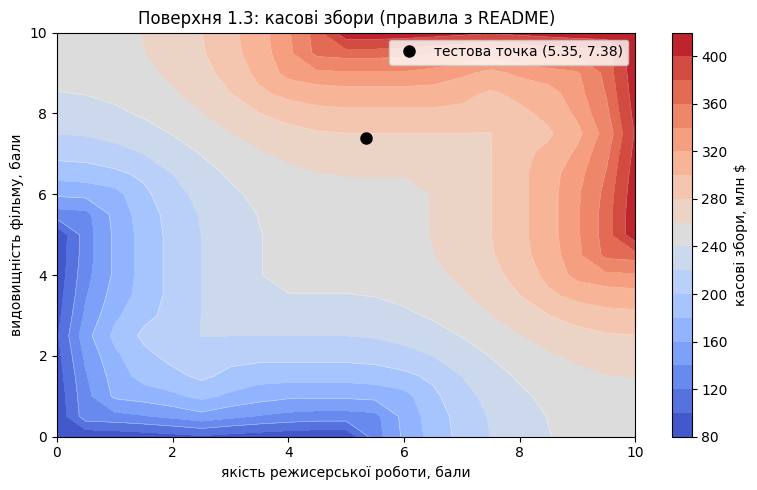

In [5]:
def surface_13(table):
    xs = np.linspace(*RANGES_13[0], 21)
    ys = np.linspace(*RANGES_13[1], 21)
    sim = fuzzy_system(*RANGES_13, table, "centroid")
    Z = np.zeros((len(ys), len(xs)))
    for i, y_val in enumerate(ys):
        for j, x_val in enumerate(xs):
            sim.input["x"] = x_val
            sim.input["y"] = y_val
            sim.compute()
            Z[i, j] = sim.output["z"]
    return xs, ys, Z

xs, ys, Z_old = surface_13(TABLE_13)

fig, ax = plt.subplots(figsize=(8, 5))
cf = ax.contourf(xs, ys, Z_old, levels=20, cmap="coolwarm")
ax.contour(xs, ys, Z_old, levels=10, colors="white", linewidths=0.4, alpha=0.5)
fig.colorbar(cf, ax=ax, label="касові збори, млн $")
ax.plot(out_11, out_12, "ko", markersize=8, label=f"тестова точка ({out_11:.2f}, {out_12:.2f})")
ax.set_xlabel("якість режисерської роботи, бали")
ax.set_ylabel("видовищність фільму, бали")
ax.set_title("Поверхня 1.3: касові збори (правила з README)")
ax.legend()
fig.tight_layout()
plt.savefig("task21_mf.png", dpi=100, bbox_inches="tight")
plt.show()

### 4. Одне правило

Порівняння до/після зміни правила 1.3:
  центроїд:         було 276.9289 → стало 403.8532 млн $  (різниця +126.9243)
  середнє максимумів: було 250.0000 → стало 440.0180 млн $  (різниця +190.0180)


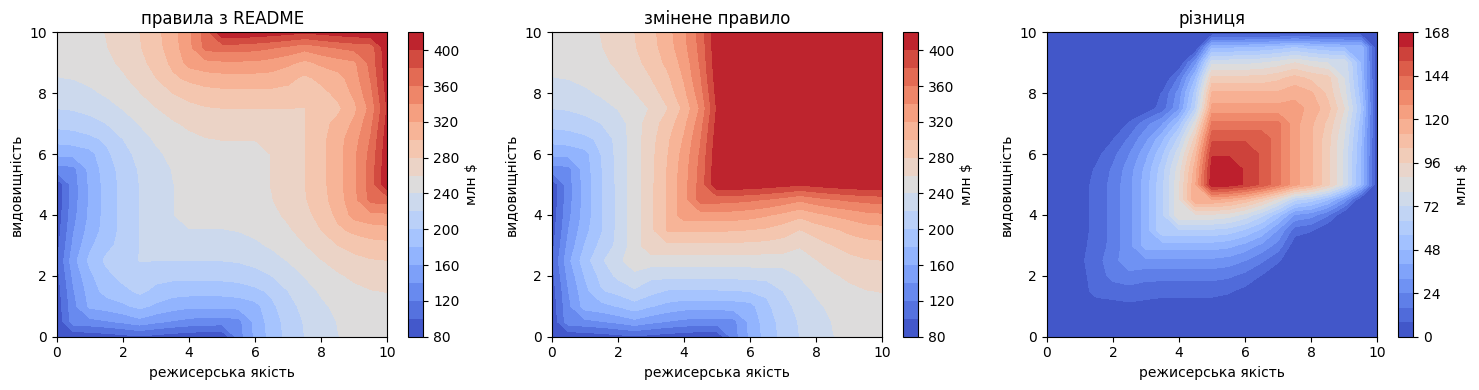

In [6]:
# Змінюємо правило 1.3: рядок «середній», стовпець «середній» → «високий»
TABLE_13_NEW = [row[:] for row in TABLE_13]
TABLE_13_NEW[1][1] = "високий"

new_centroid = infer(RANGES_13, TABLE_13_NEW, "centroid", out_11, out_12)
new_mom      = infer(RANGES_13, TABLE_13_NEW, "mom",      out_11, out_12)

print("Порівняння до/після зміни правила 1.3:")
print(f"  центроїд:         було {out_13_centroid:.4f} → стало {new_centroid:.4f} млн $  (різниця {new_centroid-out_13_centroid:+.4f})")
print(f"  середнє максимумів: було {out_13_mom:.4f} → стало {new_mom:.4f} млн $  (різниця {new_mom-out_13_mom:+.4f})")

_, _, Z_new = surface_13(TABLE_13_NEW)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, Z, title in [
    (axes[0], Z_old, "правила з README"),
    (axes[1], Z_new, "змінене правило"),
    (axes[2], Z_new - Z_old, "різниця"),
]:
    cf = ax.contourf(xs, ys, Z, levels=20, cmap="coolwarm")
    fig.colorbar(cf, ax=ax, label="млн $")
    ax.set_xlabel("режисерська якість")
    ax.set_ylabel("видовищність")
    ax.set_title(title)
fig.tight_layout()
plt.savefig("task21_inference.png", dpi=100, bbox_inches="tight")
plt.show()

## Частина 2. Нейро-нечітка модель

### 5. Дані

In [7]:
sample = pd.read_csv("sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_tr = (X_tr - x_min) / (x_max - x_min)
x_te = (X_te - x_min) / (x_max - x_min)

y_min  = y_tr.min()
y_span = y_tr.max() - y_tr.min()
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

rmse_mean_tr = float(np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2)))
rmse_mean_te = float(np.sqrt(np.mean((y_te - y_tr.mean()) ** 2)))

print(f"Навчальна: {X_tr.shape[0]} × {X_tr.shape[1]},  тестова: {X_te.shape[0]} × {X_te.shape[1]}")
print(f"y_span = {y_span:.4f} тис. грн")
print(f"RMSE прогнозу середнім — навчальна: {rmse_mean_tr:.4f},  тестова: {rmse_mean_te:.4f}")

Навчальна: 45 × 4,  тестова: 16 × 4
y_span = 4.6740 тис. грн
RMSE прогнозу середнім — навчальна: 1.0168,  тестова: 0.8919


In [8]:
# Ядро моделі Сугено (готове)
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]

def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))

def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span

def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta

def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

print("Ядро моделі готове.")

Ядро моделі готове.


### 6. Субтрактивна кластеризація

In [9]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

data_sc = np.column_stack([x_tr, t_tr])
for ra in (0.3, 0.5, 0.8):
    c = len(subclust(data_sc, ra))
    print(f"ra = {ra}  →  {c} правил")

ra = 0.3  →  28 правил
ra = 0.5  →  8 правил
ra = 0.8  →  3 правил


### 7. Правила з c-means і налаштування

In [10]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(
        np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([
        np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())
        for k in range(c)
    ])
    return pack(centers, np.clip(widths, 0.08, 0.8))

theta       = cmeans_rules(3)
theta_tuned = tune(theta, 3)

tr_b, te_b = errors(theta, 3)
tr_a, te_a = errors(theta_tuned, 3)

rows_m = [
    {"Модель": "прогноз середнім",                   "Навчальна": rmse_mean_tr, "Тестова": rmse_mean_te},
    {"Модель": "3 правила c-means, до налаштування",  "Навчальна": tr_b,         "Тестова": te_b},
    {"Модель": "3 правила c-means, після налаштування","Навчальна": tr_a,         "Тестова": te_a},
]
df_m = pd.DataFrame(rows_m)
print(df_m.round(4).to_string(index=False))

                               Модель  Навчальна  Тестова
                     прогноз середнім     1.0168   0.8919
   3 правила c-means, до налаштування     0.7801   0.7935
3 правила c-means, після налаштування     0.4858   1.1160


### 8. Кількість правил

 Правил  Навчальна  Тестова
      2     0.6853   0.8423
      3     0.4858   1.1160
      4     0.4751   1.1655
      5     0.3847   0.8045
      6     0.2975   0.9694


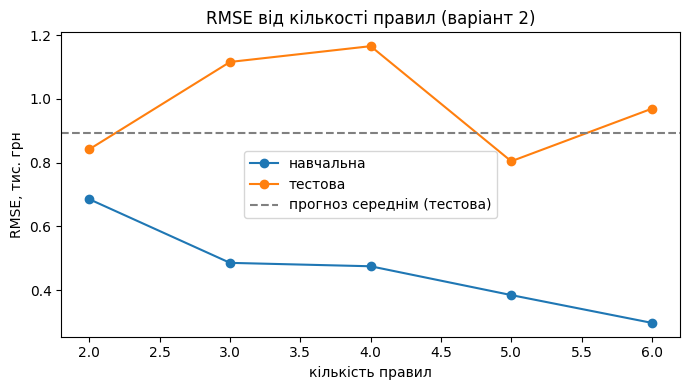

In [11]:
rule_rows = []
for c in range(2, 7):
    th = tune(cmeans_rules(c), c)
    tr_e, te_e = errors(th, c)
    rule_rows.append({"Правил": c, "Навчальна": round(tr_e, 4), "Тестова": round(te_e, 4)})

rules_df = pd.DataFrame(rule_rows)
print(rules_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rules_df["Правил"], rules_df["Навчальна"], marker="o", label="навчальна")
ax.plot(rules_df["Правил"], rules_df["Тестова"],   marker="o", label="тестова")
ax.axhline(rmse_mean_te, color="gray", linestyle="--", label="прогноз середнім (тестова)")
ax.set_xlabel("кількість правил")
ax.set_ylabel("RMSE, тис. грн")
ax.set_title("RMSE від кількості правил (варіант 2)")
ax.legend()
fig.tight_layout()
plt.savefig("anfis_training_error.png", dpi=100, bbox_inches="tight")
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

In [12]:
FUND     = (8, 5, 5)   # фонд часу бригад, год (з README варіанта 2)
TIME_DIV = 8           # дільник (з README варіанта 2)

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample["service_cost_kuah"].to_numpy()

print(f"Об'єктів: {len(t)},  сумарний час: {t.sum():.2f} год,  фонд: {sum(FUND)} год")

Об'єктів: 61,  сумарний час: 164.79 год,  фонд: 18 год


In [13]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]

def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))

def value(plan):
    return float(v[plan > 0].sum())

def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx  = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

print("Допоміжні функції готові.")

Допоміжні функції готові.


In [14]:
plan_greedy = np.zeros(len(t), dtype=int)
used_b = [0.0, 0.0, 0.0]
for i in np.argsort(-(v / t)):
    for b in range(3):
        if used_b[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            used_b[b] += t[i]
            break

ld = load(plan_greedy)
print(f"Жадібний: сума={value(plan_greedy):.4f},  "
      f"завантаження={[round(x,3) for x in ld]},  перевищення={overflow(plan_greedy):.4f}")

Жадібний: сума=24.5870,  завантаження=[7.277, 4.402, 4.922],  перевищення=0.0000


### 10. Генетичний алгоритм

In [15]:
def run_ga(fitness):
    ga = pygad.GA(
        num_generations=250, sol_per_pop=120, num_parents_mating=60,
        num_genes=len(t), gene_type=int, gene_space=[0, 1, 2, 3],
        fitness_func=fitness,
        parent_selection_type="tournament", K_tournament=3,
        crossover_type="uniform",
        mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
        keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)

plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
ld = load(plan_repair)
print(f"ГА з ремонтом: сума={value(plan_repair):.4f},  "
      f"завантаження={[round(x,3) for x in ld]},  перевищення={overflow(plan_repair):.4f}")

ГА з ремонтом: сума=25.0440,  завантаження=[7.919, 4.68, 4.765],  перевищення=0.0000


In [16]:
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
ld = load(plan_penalty)
print(f"ГА зі штрафом: сума={value(plan_penalty):.4f},  "
      f"завантаження={[round(x,3) for x in ld]},  перевищення={overflow(plan_penalty):.4f}")

ГА зі штрафом: сума=17.5660,  завантаження=[7.035, 5.134, 4.84],  перевищення=0.1341


### 11. Точний оптимум

In [17]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows),
                                            [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

plan_optimum = optimum()
best = value(plan_optimum)

plans = [
    ("жадібний алгоритм", plan_greedy),
    ("ГА з ремонтом",     plan_repair),
    ("ГА зі штрафом",     plan_penalty),
    ("оптимум",           plan_optimum),
]
rows_p = []
for name, p in plans:
    ld = load(p)
    rows_p.append({
        "План": name,
        "Сума, тис. грн": round(value(p), 3),
        "Завантаження, год": "/".join(f"{x:.2f}" for x in ld),
        "Перевищення, год": round(overflow(p), 4),
        "% оптимуму": round(100 * value(p) / best, 1),
    })
print(pd.DataFrame(rows_p).to_string(index=False))

             План  Сума, тис. грн Завантаження, год  Перевищення, год  % оптимуму
жадібний алгоритм          24.587    7.28/4.40/4.92            0.0000        96.1
    ГА з ремонтом          25.044    7.92/4.68/4.76            0.0000        97.9
    ГА зі штрафом          17.566    7.04/5.13/4.84            0.1341        68.7
          оптимум          25.586    7.96/4.78/4.71            0.0000       100.0


### 12. Самоперевірка й збереження

In [18]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 25.044 з оптимуму 25.586
